# 07 · Evaluation

1. Accuracy of every model on all 66 origins (MAE, RMSE, MAPE, 80% coverage, skill vs naive)
2. Diebold–Mariano tests (HLN-corrected, Newey–West variance with h−1 lags) vs naive and vs the best conventional model
3. Forecast combination: best conventional + best AI model
4. Robustness: ARIMAX without the most recent crude week

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from common import *
import plots; plots.setup()
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
df = load_weekly()

## 1. Accuracy, all 66 origins

In [2]:
fc = attach_actuals(load_forecasts(), df)
full_models = [m for m in fc.model.unique() if not m.startswith("llm_")]
FULL = fc[fc.model.isin(full_models)]
def table(d):
    t = d[d.horizon.isin(SCORED_H)].groupby(["horizon", "model"]).apply(metrics)
    t["skill_vs_naive"] = t["MAE"] / t.index.get_level_values("horizon").map(t["MAE"].xs("naive", level="model"))
    return t
tab = table(FULL)
m4 = tab.xs(4, level="horizon")
conv = [m for m in m4.index if m in ("ets", "arima_fourier", "arimax")]
ai = [m for m in m4.index if m in ("chronos_bolt", "moirai2")]
best_conv, best_ai = m4.loc[conv, "MAE"].idxmin(), m4.loc[ai, "MAE"].idxmin()
print("best conventional:", best_conv, "| best AI (full coverage):", best_ai)

best conventional: arimax | best AI (full coverage): chronos_bolt


## 2. Forecast combination

In [3]:
combo = (FULL[FULL.model.isin([best_conv, best_ai])]
         .groupby(["origin_date", "horizon", "target_date"], as_index=False)[["forecast", "lower80", "upper80"]].mean())
combo.insert(0, "model", "combo")
combo[FC_COLS].to_csv(FC_DIR / "combo.csv", index=False, date_format="%Y-%m-%d")
fc = attach_actuals(load_forecasts(), df)
FULL = fc[~fc.model.str.startswith("llm_")]
tab = table(FULL).round(3).sort_values(["horizon", "MAE"])
tab.to_csv(RES_DIR / "metrics.csv"); tab

n    MAE   RMSE    MAPE   bias  cover80  skill_vs_naive
horizon model                                                                      
4       arimax           63.0  0.213  0.305   4.030  0.116    0.889           0.788
        arima_fourier    63.0  0.217  0.311   4.104  0.105    0.810           0.804
        arimax_lags1to4  63.0  0.218  0.309   4.125  0.105    0.825           0.807
        combo            63.0  0.237  0.336   4.501  0.145    0.794           0.875
        ets              63.0  0.268  0.364   5.199  0.076    0.651           0.992
        naive            63.0  0.270  0.384   5.233  0.111    0.794           1.000
        chronos_bolt     63.0  0.277  0.384   5.308  0.174    0.683           1.025
        moirai2          63.0  0.279  0.389   5.296  0.172    0.730           1.031
        seasonal_naive   63.0  0.631  0.848  11.421  0.574    0.968           2.335
12      arimax           55.0  0.397  0.573   7.265  0.351    0.745           0.662
        arimax_lags1to4  55.0  0.410  0.577   7.509  0.332    0.745           0.683
        arima_fourier    55.0  0.412  0.581   7.551  0.340    0.745           0.686
        combo            55.0  0.467  0.693   8.424  0.402    0.709           0.778
        chronos_bolt     55.0  0.579  0.829  10.592  0.453    0.691           0.966
        naive            55.0  0.600  0.812  11.109  0.294    0.782           1.000
        moirai2          55.0  0.639  0.877  11.717  0.533    0.709           1.065
        ets              55.0  0.694  0.879  12.944  0.232    0.655           1.157
        seasonal_naive   55.0  0.715  0.907  12.895  0.665    0.964           1.192

## 3. Diebold–Mariano tests

In [4]:
rows = []
for h in SCORED_H:
    e = fc[fc.horizon == h].pivot(index="origin_date", columns="model", values="error")
    for m in e.columns:
        for bench in ["naive", best_conv]:
            if m != bench:
                pair = e[[m, bench]].dropna()
                if len(pair) > h + 2:
                    s, p = dm_test(pair[m].values, pair[bench].values, h)
                    rows.append({"horizon": h, "model": m, "vs": bench, "n": len(pair), "DM": s, "p": p})
dm = pd.DataFrame(rows).round(3); dm.to_csv(RES_DIR / "dm_tests.csv", index=False)
dm[dm.p < 0.10]

,horizon,model,vs,n,DM,p
0,4,arima_fourier,naive,63,-1.787,0.079
2,4,arimax,naive,63,-1.965,0.054
3,4,arimax_lags1to4,naive,63,-1.856,0.068
6,4,chronos_bolt,arimax,63,2.652,0.010
8,4,combo,arimax,63,2.332,0.023
10,4,ets,arimax,63,2.653,0.010
12,4,llm_anon,arimax,16,1.882,0.079
16,4,moirai2,arimax,63,2.294,0.025
17,4,naive,arimax,63,1.965,0.054
18,4,seasonal_naive,naive,63,2.926,0.005


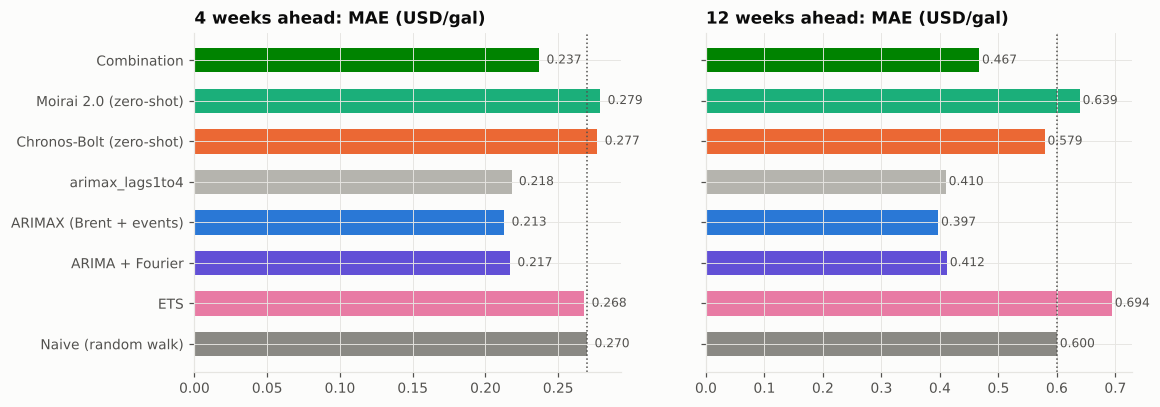

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
order = ["naive", "seasonal_naive", "ets", "arima_fourier", "arimax", "arimax_lags1to4", "chronos_bolt", "moirai2", "combo"]
for ax, h in zip(axes, SCORED_H):
    d = tab.xs(h, level="horizon").reindex([m for m in order if m in tab.xs(h, level="horizon").index])
    d = d.drop(index="seasonal_naive")
    cols = [plots.MODEL_COLORS.get(m, "#b5b4ae") for m in d.index]
    ax.barh([plots.MODEL_LABELS.get(m, m) for m in d.index], d["MAE"], color=cols, height=0.6)
    ax.axvline(d.loc["naive", "MAE"], color=plots.INK2, ls=":", lw=1)
    for y, v in enumerate(d["MAE"]): ax.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=8, color=plots.INK2)
    ax.set_title(f"{h} weeks ahead: MAE (USD/gal)", fontsize=11); ax.invert_yaxis()
plots.save(fig, FIG_DIR / "fig09_mae.png"); fig

## 4. Robustness: does the most recent crude week matter?

In [6]:
r = tab.loc[(slice(None), ["arima_fourier", "arimax", "arimax_lags1to4"]), ["MAE", "RMSE", "cover80", "skill_vs_naive"]]
r

,,MAE,RMSE,cover80,skill_vs_naive
horizon,model,,,,
4,arima_fourier,0.217,0.311,0.810,0.804
12,arima_fourier,0.412,0.581,0.745,0.686
4,arimax,0.213,0.305,0.889,0.788
12,arimax,0.397,0.573,0.745,0.662
4,arimax_lags1to4,0.218,0.309,0.825,0.807
12,arimax_lags1to4,0.410,0.577,0.745,0.683


Dropping the most recent crude week known at the origin (lags 1–4 instead of 0–3) removes ARIMAX's advantage over ARIMA: the latest week carries the strongest crude signal (cross-correlation 0.34, notebook 02).

**Diebold–Mariano variance.** Newey–West (Bartlett) weights with h−1 lags are used. With unweighted autocovariances, the long-run variance can collapse toward zero at h = 12 with ~55 overlapping forecasts (e.g. Moirai 2.0 vs naive would give DM ≈ 10.8), so Bartlett weights are the safer choice.